# Milestone 2 - Fine-tune Stable Diffusion with LoRA

This notebook builds on the pretrained text-conditional Stable Diffusion 1.5 pipeline. It freezes the CLIP text encoder, VAE, and pretrained U-Net weights, and trains small LoRA adapters on the U-Net attention projections using only Flickr30k training pairs. The baseline remains in notebook 03 for a later same-prompt comparison.

Architecture: caption -> CLIP tokenizer -> 77 token hidden states -> U-Net cross-attention with a noisy image latent -> denoised latent -> VAE decoder -> image. See `docs/m2_integration_architecture.md` for the full data flow and training details.

## 1. Environment and prerequisites

Use a CUDA GPU runtime (a Colab T4 is recommended). Clone/open this repository and run notebook cells from its root directory. Run notebook 01 first so `data/flickr30k_subset/metadata.csv` and `data/flickr30k_subset/images/` are available. Notebook 03 is the unchanged pretrained baseline; run it before fine-tuning when collecting comparison results.

In [10]:
!pip install -U -q "diffusers>=0.30.0" "transformers>=4.40.0" accelerate peft pandas pillow safetensors "torchao>=0.4.0"

In [ ]:
!unzip -q data/flickr30k_subset.zip -d data/

replace data/sample_pairs.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [11]:
import shutil
from pathlib import Path

# Define target directory
target_dir = Path("data/flickr30k_subset")
target_dir.mkdir(parents=True, exist_ok=True)

# Move metadata.csv
if Path("data/metadata.csv").is_file():
    shutil.move("data/metadata.csv", target_dir / "metadata.csv")
    print("Moved metadata.csv")

# Move dataset_config.json
if Path("data/dataset_config.json").is_file():
    shutil.move("data/dataset_config.json", target_dir / "dataset_config.json")
    print("Moved dataset_config.json")

# Move images directory
if Path("data/images").is_dir():
    shutil.move("data/images", target_dir / "images")
    print("Moved images directory")


In [12]:
from pathlib import Path
import torch

assert torch.cuda.is_available(), "Select a CUDA GPU runtime before training."
assert Path("scripts/train_sd_lora.py").is_file(), "Run this notebook from the repository root."
assert Path("data/flickr30k_subset/metadata.csv").is_file(), "Run notebook 01 to prepare the dataset first."
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset and training script found.")

GPU: Tesla T4
Dataset and training script found.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Train U-Net LoRA adapters

The default is a bounded first experiment: 800 optimizer updates, batch size 1, rank 8, and learning rate 1e-4. Raise `TRAIN_STEPS` only after reviewing the first run's loss and held-out generations. The script checks the dataset and GPU explicitly and writes the adapter, configuration, and loss log to an ignored `models/` directory.

In [14]:
with open('/content/scripts/train_sd_lora.py', 'r') as f:
    script_content = f.read()

# Replace the old enable_gradient_checkpointing call with the compatible version
updated_content = script_content.replace(
    'unet.enable_gradient_checkpointing(gradient_checkpointing_kwargs={"use_reentrant": False})',
    'unet.enable_gradient_checkpointing()'
)

with open('/content/scripts/train_sd_lora.py', 'w') as f:
    f.write(updated_content)

print("Successfully patched scripts/train_sd_lora.py to fix gradient checkpointing argument compatibility!")

Successfully patched scripts/train_sd_lora.py to fix gradient checkpointing argument compatibility!


In [15]:
TRAIN_STEPS = 800
OUTPUT_DIR = Path("models/sd15-flickr30k-lora")

!python scripts/train_sd_lora.py --train-steps {TRAIN_STEPS} --output-dir models/sd15-flickr30k-lora

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
GPU: Tesla T4 | dtype: torch.float16
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Loading weights: 100% 196/196 [00:01<00:00, 109.46it/s]
Training 1,594,368 / 861,115,332 U-Net parameters with LoRA
Training examples: 1600 | optimizer updates: 800
step 0025/800 | mean loss 0.19604
step 0050/800 | mean loss 0.16248
step 0075/800 | mean loss 0.19757
step 0100/800 | mean loss 0.23768
step 0125/800 | mean loss 0.17787
step 0150/800 | mean loss 0.18552
step 0175/800 | m

## 3. Load the adapter and preview a validation caption

This sanity check loads the saved adapter into the original pretrained pipeline and generates one validation caption. It does not replace the systematic baseline-versus-fine-tuned evaluation; use identical prompts and seeds for that comparison.

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Three boys wearing green shirts and tan pants pose at the top of a slide


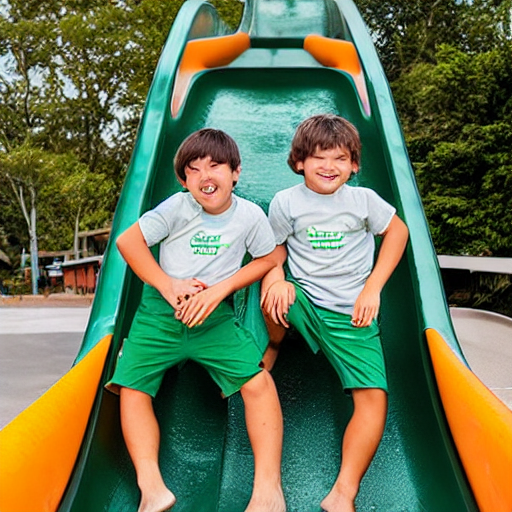

In [16]:
import pandas as pd
from diffusers import StableDiffusionPipeline
from IPython.display import display

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
dtype = torch.float16
pipeline = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=dtype).to("cuda")
pipeline.load_lora_weights(str(OUTPUT_DIR))
pipeline.set_progress_bar_config(disable=True)

metadata = pd.read_csv("data/flickr30k_subset/metadata.csv")
validation = metadata.loc[metadata["split"] == "val"].reset_index(drop=True)
assert not validation.empty, "Dataset has no validation captions."
preview_prompt = validation.loc[0, "caption"]
generator = torch.Generator(device="cuda").manual_seed(42)
preview = pipeline(preview_prompt, num_inference_steps=30, guidance_scale=7.5, generator=generator).images[0]
preview.save(OUTPUT_DIR / "validation_preview.png")
print(preview_prompt)
display(preview)

## 4. Check prompt conditioning on held-out captions

A completed training run and a single plausible image do not prove prompt adherence. This evaluation uses six fixed captions from the validation split and the same random seed for each caption across three conditions: pretrained model + correct caption, LoRA model + correct caption, and LoRA model + empty prompt. It reports CLIP matching and mismatched-caption scores and top-1 retrieval, and saves a side-by-side grid for human review. Correct-caption outputs should score above the empty-prompt control and mismatched captions; the LoRA is not expected to beat the pretrained model on every metric.

In [ ]:
import subprocess
import sys

# Free the pipeline's GPU memory; the evaluation script loads its own pipeline and CLIP scorer.
pipeline.to("cpu")
torch.cuda.empty_cache()
subprocess.run([
    sys.executable,
    "scripts/evaluate_sd_conditioning.py",
    "--data-dir", "data/flickr30k_subset",
    "--adapter-dir", str(OUTPUT_DIR),
    "--output-dir", str(OUTPUT_DIR / "conditioning_eval"),
    "--num-prompts", "6",
], check=True)